In [1]:
import pandas as pd
import numpy as np
import os
from pathlib import Path
from tqdm import tqdm
import random

from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import mannwhitneyu

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor 
import networkx as nx
from networkx.algorithms import approximation

import shap
shap.initjs()

/home1/jinyiy/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Get target users adoptions & interactions

In [14]:
# all study URLs: shared >10 times
df = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/all_urls_count_covid.csv")
df = df.sort_values(by='count', ascending=False)
df = df[df['count'] > 10]

In [ ]:
# all study users: shared >10 urls
df = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/over10_adoptions_election.csv", dtype=str)

In [19]:
grouped_result = df.groupby('userid').size().reset_index(name='count')
grouped_result = grouped_result[grouped_result['count'] > 10]

In [22]:
grouped_result.to_csv("/scratch2/jinyiy/susceptibility_study_2/target_users_election.csv", index=False)

In [2]:
# get target users all adoptions
df = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/target_users_covid.csv", dtype=str)
target_users = df['userid'].tolist()
df = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/over10_adoptions_covid.csv", dtype=str)

In [3]:
df = df[df['userid'].isin(target_users)]

In [5]:
df.to_csv("/scratch2/jinyiy/susceptibility_study_2/target_users_all_adoptions_covid.csv", index=False)

In [6]:
# get target users first adoption
df = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/target_users_all_adoptions_covid.csv", dtype=str)

In [ ]:
df['date'] = pd.to_datetime(df['date'])
df = df[df['date'] > pd.Timestamp('2020-03-01')]
df = df.sort_values('date').groupby(['userid', 'expanded_urls_list']).first().reset_index()

In [8]:
df.to_csv("/scratch2/jinyiy/susceptibility_study_2/target_users_first_adoptions_covid.csv", index=False)

In [6]:
# get target users' first interactions with other users
df = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/target_users_all_adoptions_covid.csv", dtype=str)
df['date'] = pd.to_datetime(df['date'])

In [7]:
df = df[~(df['tweet_type'] == 'original')]
df = df.sort_values('date').groupby(['userid', 'referenced_userid']).first().reset_index()
df = df[['userid', 'referenced_userid', 'date', 'tweet_type']]

In [8]:
df.to_csv("/home1/jinyiy/susceptibility/sus_study_2/target_users_first_interaction_covid.csv", index=False)

### Get exposures

In [15]:
target_adoption_df_first = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/target_users_first_adoptions_covid.csv", dtype=str)
interaction_df = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/target_users_first_interaction_covid.csv", dtype=str)
all_adoption_df_all = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/over10_adoptions_covid.csv", dtype=str)

In [16]:
target_adoption_df_first['date'] = pd.to_datetime(target_adoption_df_first['date'])
interaction_df['date'] = pd.to_datetime(interaction_df['date'])
all_adoption_df_all['date'] = pd.to_datetime(all_adoption_df_all['date'])

In [17]:
target_users = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/target_users_covid.csv", dtype=str)
target_users = target_users['userid'].tolist()[:30000]

In [18]:
interaction_df = interaction_df[interaction_df['userid'].isin(target_users)]
target_adoption_df_first = target_adoption_df_first[target_adoption_df_first['userid'].isin(target_users)]
referenced_users = interaction_df['referenced_userid'].tolist()
all_adoption_df_all = all_adoption_df_all[all_adoption_df_all['userid'].isin(referenced_users)]

In [ ]:
exposure_df = pd.DataFrame()

for userid in tqdm(target_users):
    print(userid)
    # Filter interaction_df for matching userid and earlier timePublished
    filtered_interaction_df = interaction_df[(interaction_df['userid'] == userid)]
    print("get interactions")
    interaction_dict = pd.Series(filtered_interaction_df['date'].values, index=filtered_interaction_df['referenced_userid']).to_dict()
    print("get dict")
    filtered_interaction_df = pd.DataFrame(list(interaction_dict.items()), columns=['userid', 'min_date'])
    merged_df = all_adoption_df_all.merge(filtered_interaction_df, on='userid', how='inner')
    all_adoption_df_filtered = merged_df[merged_df['date'] > merged_df['min_date']].copy()
    print("get exposures")
    all_adoption_df_filtered['exposed_userid'] = userid

    df = pd.merge(all_adoption_df_filtered, target_adoption_df_first[['userid', 'expanded_urls_list', 'date']], 
                     left_on=['exposed_userid', 'expanded_urls_list'], 
                     right_on=['userid', 'expanded_urls_list'],
                     how='left', 
                     indicator=True)
    df = df[(df['_merge'] == 'left_only') | (df['date_x'] < df['date_y'])]
    df = df.drop(['userid_y', 'date_y', '_merge'], axis=1).rename(columns={'date_x': 'date'})
    df['expanded_urls_list'] = df['expanded_urls_list'].str.lower()
    df = df.groupby(['exposed_userid', 'expanded_urls_list']).size().reset_index(name='count')
    
    exposure_df = pd.concat([exposure_df, df], ignore_index=True)

### IAR and SAR

In [ ]:
import pandas as pd
import numpy as np
import os
from tqdm import tqdm

folder_path = "/scratch2/jinyiy/susceptibility_study_2/exposure_election"
file_list = sorted(os.listdir(folder_path))
large_df = pd.DataFrame()

all_adoption_df_all = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/over10_adoptions_election.csv", dtype=str)
all_adoption_df_all['combined_key'] = all_adoption_df_all['userid'].astype(str) + "_" + all_adoption_df_all['expanded_urls_list'].astype(str)

for filename in tqdm(file_list):
    if filename.endswith('.csv'):
        file_path = os.path.join(folder_path, filename)
        try:
            print(filename, "processing...")
            df = pd.read_csv(file_path, dtype=str)
            df['count'] = df['count'].astype(int)
            df['combined_key'] = df['exposed_userid'].astype(str) + "_" + df['expanded_urls_list'].astype(str)
            all_adoption_keys = set(all_adoption_df_all['combined_key'])
            df['success_exp'] = df['combined_key'].apply(lambda x: x in all_adoption_keys)
            df.drop('combined_key', axis=1, inplace=True)
            grouped = df.groupby('exposed_userid')
            true_sum = grouped.apply(lambda x: x[x['success_exp']]['count'].sum())
            total_sum = grouped['count'].sum()
            ratio = true_sum / total_sum
            convertibility_df = pd.DataFrame({
                'userid': ratio.index,
                'convertibility': ratio.values
            })
            large_df = pd.concat([large_df, convertibility_df], ignore_index=True)
            print(filename, "DONE")
        except Exception as e:
            print(f"Error processing file {filename}: {e}")

large_df.to_csv("/scratch2/jinyiy/susceptibility_study_2/IAR_score_election.csv", index=False)

In [3]:
IAR_df = pd.read_csv("/scratch1/jinyiy/susceptibility_study_2/IAR_score_election.csv")

In [ ]:
#plt.rcParams['font.family'] = 'Verdana'
plt.figure(figsize=(4, 4))

sns.histplot(data=IAR_df, x='IAR', bins=50)
plt.xlabel('Influence-driven Adoption Rate (IAR)')
plt.ylabel('Log Frequency')
plt.yscale('log')
plt.title('Election Dataset')
plt.show()

In [20]:
target_adoption_df = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/target_users_first_adoptions_covid.csv", dtype=str)
success_exposure_df = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/successful_exposure_covid.csv", dtype=str)

target_adoption_df = target_adoption_df.merge(success_exposure_df, 
                                      left_on=['userid', 'expanded_urls_list'],
                                      right_on=['exposed_userid', 'expanded_urls_list'],
                                      how='left')

target_adoption_df['success_exp'].fillna(False, inplace=True)
target_adoption_df['success_exp'] = target_adoption_df['success_exp'].astype(bool)
target_adoption_df['success_exp'].value_counts()

SAR_df = target_adoption_df.groupby('userid')['success_exp'].apply(lambda x: (x == True).sum() / len(x)).reset_index()
SAR_df.rename(columns={'success_exp': '1-SAR'}, inplace=True)
SAR_df['SAR'] = 1 - SAR_df['1-SAR']

SAR_df.to_csv("/scratch2/jinyiy/susceptibility_study_2/SAR_score_covid.csv", index=False)

In [8]:
SAR_df = pd.read_csv("/scratch2/jinyiy/susceptibility_study_2/SAR_score_covid.csv")

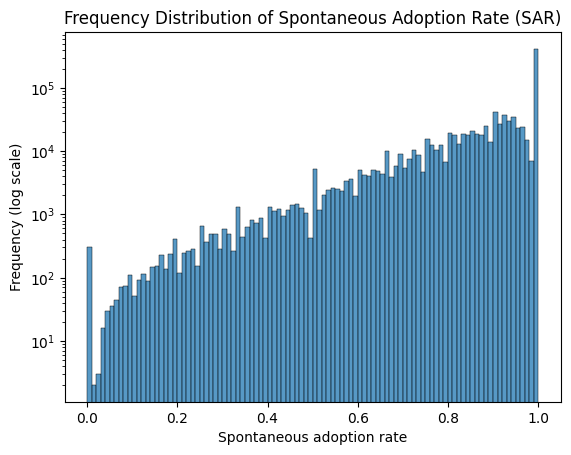

In [9]:
sns.histplot(data=SAR_df, x='SAR', bins=100)
plt.xlabel('Spontaneous adoption rate')
plt.ylabel('Frequency (log scale)')
plt.yscale('log')
plt.title('Frequency Distribution of Spontaneous Adoption Rate (SAR)')
plt.show()

### RQ1: IAR & SAR Correlation

In [14]:
IAR_df = pd.read_csv("/scratch1/jinyiy/susceptibility_study_2/IAR_score_covid.csv")
SAR_df = pd.read_csv("/scratch1/jinyiy/susceptibility_study_2/SAR_score_covid.csv")

merged_df = IAR_df.merge(SAR_df, on='userid', how='left')
merged_df.dropna(subset=['IAR', 'SAR'], inplace=True)
merged_df['IAR'] = pd.to_numeric(merged_df['IAR'], errors='coerce')
merged_df['SAR'] = pd.to_numeric(merged_df['SAR'], errors='coerce')
merged_df['1-SAR'] = pd.to_numeric(merged_df['1-SAR'], errors='coerce')

from scipy.stats import spearmanr
correlation, p_value = spearmanr(merged_df['IAR'], merged_df['SAR'])
print(f"Spearman Correlation: {correlation:.3f}")
print(f"P-Value: {p_value}")

Spearman Correlation: -0.857
P-Value: 0.0


### RQ2: Susceptibility homophily

In [8]:
IAR_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/IAR_score_election.csv")
IAR_df['userid'] = IAR_df['userid'].astype(str)
SAR_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/SAR_score_election.csv")
SAR_df['userid'] = SAR_df['userid'].astype(str)
IAR_users = set(IAR_df['userid'])
SAR_users = set(SAR_df['userid'])
target_users = IAR_users.intersection(SAR_users)
target_users = list(target_users)

In [4]:
with open('/project/emiliofe_74/jinyiy/susceptibility_study_2/target_users_election_over5.txt', 'r') as file:
    target_users_5 = file.readlines()
target_users_5 = [line.strip() for line in target_users_5]
target_users = list(set(target_users_5) & set(target_users))

In [27]:
interaction_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/target_users_all_adoptions_election.csv", dtype=str)
interaction_df = interaction_df[['userid', 'referenced_userid', 'date', 'tweet_type']]
interaction_df = interaction_df[interaction_df['userid'].isin(target_users) & interaction_df['referenced_userid'].isin(target_users)]

In [28]:
pair_set = set(zip(interaction_df['userid'], interaction_df['referenced_userid']))

In [29]:
pair_set = {(a, b) for (a, b) in pair_set if a != b}

In [30]:
filtered_pairs_set = {(a, b) for (a, b) in pair_set if (b, a) in pair_set}

In [31]:
filtered_df = pd.DataFrame(filtered_pairs_set, columns=['userid', 'referenced_userid'])
filtered_interaction_df = interaction_df[
    interaction_df[['userid', 'referenced_userid']].apply(tuple, axis=1).isin(filtered_df.apply(tuple, axis=1))
]

In [32]:
retweet_df = filtered_interaction_df[filtered_interaction_df['tweet_type'] == 'retweeted_tweet_without_comment']
#quoted_df = interaction_df[interaction_df['tweet_type'] == 'quoted_tweet']
#reply_df = interaction_df[interaction_df['tweet_type'] == 'reply']
mention_df = filtered_interaction_df[(filtered_interaction_df['tweet_type'] == 'reply') | (interaction_df['tweet_type'] == 'quoted_tweet')]

/tmp/SLURM_25465726/ipykernel_177553/1258574482.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  mention_df = filtered_interaction_df[(filtered_interaction_df['tweet_type'] == 'reply') | (interaction_df['tweet_type'] == 'quoted_tweet')]


In [55]:
def IAR(df):
    df = df.drop_duplicates(subset=['userid', 'referenced_userid'])
    df = df.merge(IAR_df, on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_1'}, inplace=True)
    df = df.merge(IAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_2'}, inplace=True)

    print("Nodes:", len(set(df['userid_x'].unique()) | set(df['referenced_userid'].unique())))
    print("Edges:", len(df))
    
    correlation_coefficient, p_value = pearsonr(df['IAR_1'], df['IAR_2'])
    print(f"Pearson Correlation Coefficient: {correlation_coefficient:.3f}")
    print(f"P-Value: {p_value:.4f}")

In [9]:
IAR(filtered_interaction_df)

Nodes: 965314
Edges: 17279562
Pearson Correlation Coefficient: 0.045
P-Value: 0.0000


In [10]:
IAR(retweet_df)

Nodes: 913055
Edges: 11348079
Pearson Correlation Coefficient: 0.046
P-Value: 0.0000


In [11]:
IAR(mention_df)

Nodes: 716114
Edges: 6377521
Pearson Correlation Coefficient: 0.038
P-Value: 0.0000


In [109]:
def SAR(df):
    df = df.drop_duplicates(subset=['userid', 'referenced_userid'])
    df = df.merge(SAR_df, on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_1'}, inplace=True)
    df = df.merge(SAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_2'}, inplace=True)

    print("Nodes:", len(set(df['userid_x'].unique()) | set(df['referenced_userid'].unique())))
    print("Edges:", len(df))
    
    correlation_coefficient, p_value = pearsonr(df['SAR_1'], df['SAR_2'])
    print(f"Pearson Correlation Coefficient: {correlation_coefficient:.3f}")
    print(f"P-Value: {p_value:.4f}")

In [110]:
SAR(filtered_interaction_df)

Nodes: 73960
Edges: 163974
Pearson Correlation Coefficient: 0.450
P-Value: 0.0000


In [111]:
SAR(retweet_df)

Nodes: 53161
Edges: 90800
Pearson Correlation Coefficient: 0.453
P-Value: 0.0000


In [112]:
SAR(mention_df)

Nodes: 56060
Edges: 81969
Pearson Correlation Coefficient: 0.327
P-Value: 0.0000


In [30]:
def robustness_check_IAR(df):
    shuffled_referenced_userid = df['referenced_userid'].sample(frac=1, random_state=42)
    shuffled_retweet_df = df.copy()
    shuffled_retweet_df['referenced_userid'] = shuffled_referenced_userid.values
    
    shuffled_retweet_df = shuffled_retweet_df.merge(IAR_df, on='userid', how='left')
    shuffled_retweet_df.rename(columns={'IAR': 'IAR_1'}, inplace=True)
    shuffled_retweet_df = shuffled_retweet_df.merge(IAR_df, left_on='referenced_userid', right_on='userid', how='left')
    shuffled_retweet_df.rename(columns={'IAR': 'IAR_2'}, inplace=True)
    
    correlation_coefficient, p_value = pearsonr(shuffled_retweet_df['IAR_1'], shuffled_retweet_df['IAR_2'])
    print(f"Pearson Correlation Coefficient: {correlation_coefficient:.3f}")
    print(f"P-Value: {p_value:.4f}")

In [31]:
robustness_check_IAR(retweet_df)

Pearson Correlation Coefficient: 0.001
P-Value: 0.6135


In [33]:
robustness_check_IAR(mention_df)

Pearson Correlation Coefficient: -0.002
P-Value: 0.3476


In [32]:
robustness_check_IAR(filtered_interaction_df)

Pearson Correlation Coefficient: 0.001
P-Value: 0.6896


In [34]:
def robustness_check_SAR(df):
    shuffled_referenced_userid = df['referenced_userid'].sample(frac=1, random_state=42)
    shuffled_retweet_df = df.copy()
    shuffled_retweet_df['referenced_userid'] = shuffled_referenced_userid.values
    
    shuffled_retweet_df = shuffled_retweet_df.merge(SAR_df, on='userid', how='left')
    shuffled_retweet_df.rename(columns={'SAR': 'SAR_1'}, inplace=True)
    shuffled_retweet_df = shuffled_retweet_df.merge(SAR_df, left_on='referenced_userid', right_on='userid', how='left')
    shuffled_retweet_df.rename(columns={'SAR': 'SAR_2'}, inplace=True)
    
    correlation_coefficient, p_value = pearsonr(shuffled_retweet_df['SAR_1'], shuffled_retweet_df['SAR_2'])
    print(f"Pearson Correlation Coefficient: {correlation_coefficient:.3f}")
    print(f"P-Value: {p_value:.4f}")

In [35]:
robustness_check_SAR(retweet_df)

Pearson Correlation Coefficient: 0.002
P-Value: 0.4184


In [36]:
robustness_check_SAR(mention_df)

Pearson Correlation Coefficient: -0.001
P-Value: 0.5495


In [37]:
robustness_check_SAR(filtered_interaction_df)

Pearson Correlation Coefficient: -0.001
P-Value: 0.6266


In [17]:
def weighted_IAR(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(IAR_df, on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_1'}, inplace=True)
    df = df.merge(IAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)
    df = df[['userid', 'referenced_userid', 'IAR_1', 'IAR_2', 'count']]
    
    def weighted_mean_friend(group):
        return (group['IAR_2'] * group['count']).sum() / group['count'].sum()
    def weighted_mean_neighbor(group):
        return (group['IAR_1'] * group['count']).sum() / group['count'].sum()
        
    result_df_1 = df.groupby(['userid', 'IAR_1']).apply(weighted_mean_friend).reset_index(name='IAR_mean')
    result_df_2 = df.groupby(['referenced_userid', 'IAR_2']).apply(weighted_mean_neighbor).reset_index(name='IAR_mean')

    correlation_coefficient, p_value = pearsonr(result_df_1['IAR_1'], result_df_1['IAR_mean'])
    print(f"Pearson Correlation Coefficient (Friend): {correlation_coefficient:.3f}")
    print(f"P-Value: {p_value:.4f}")
    
    correlation_coefficient, p_value = pearsonr(result_df_2['IAR_2'], result_df_2['IAR_mean'])
    print(f"Pearson Correlation Coefficient (Neighbor): {correlation_coefficient:.3f}")
    print(f"P-Value: {p_value:.4f}")

In [18]:
weighted_IAR(filtered_interaction_df)

/tmp/SLURM_25465726/ipykernel_177553/60768645.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df_1 = df.groupby(['userid', 'IAR_1']).apply(weighted_mean_friend).reset_index(name='IAR_mean')


Pearson Correlation Coefficient (Friend): 0.577
P-Value: 0.0000
Pearson Correlation Coefficient (Neighbor): 0.584
P-Value: 0.0000


/tmp/SLURM_25465726/ipykernel_177553/60768645.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df_2 = df.groupby(['referenced_userid', 'IAR_2']).apply(weighted_mean_neighbor).reset_index(name='IAR_mean')


In [19]:
weighted_IAR(retweet_df)

/tmp/SLURM_25465726/ipykernel_177553/60768645.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df_1 = df.groupby(['userid', 'IAR_1']).apply(weighted_mean_friend).reset_index(name='IAR_mean')


Pearson Correlation Coefficient (Friend): 0.589
P-Value: 0.0000
Pearson Correlation Coefficient (Neighbor): 0.601
P-Value: 0.0000


/tmp/SLURM_25465726/ipykernel_177553/60768645.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df_2 = df.groupby(['referenced_userid', 'IAR_2']).apply(weighted_mean_neighbor).reset_index(name='IAR_mean')


In [20]:
weighted_IAR(mention_df)

/tmp/SLURM_25465726/ipykernel_177553/60768645.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df_1 = df.groupby(['userid', 'IAR_1']).apply(weighted_mean_friend).reset_index(name='IAR_mean')


Pearson Correlation Coefficient (Friend): 0.399
P-Value: 0.0000
Pearson Correlation Coefficient (Neighbor): 0.364
P-Value: 0.0000


/tmp/SLURM_25465726/ipykernel_177553/60768645.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df_2 = df.groupby(['referenced_userid', 'IAR_2']).apply(weighted_mean_neighbor).reset_index(name='IAR_mean')


In [21]:
def weighted_SAR(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(SAR_df, on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_1'}, inplace=True)
    df = df.merge(SAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)
    df = df[['userid', 'referenced_userid', 'SAR_1', 'SAR_2', 'count']]
    
    def weighted_mean_friend(group):
        return (group['SAR_2'] * group['count']).sum() / group['count'].sum()
    def weighted_mean_neighbor(group):
        return (group['SAR_1'] * group['count']).sum() / group['count'].sum()
        
    result_df_1 = df.groupby(['userid', 'SAR_1']).apply(weighted_mean_friend).reset_index(name='SAR_mean')
    result_df_2 = df.groupby(['referenced_userid', 'SAR_2']).apply(weighted_mean_neighbor).reset_index(name='SAR_mean')

    correlation_coefficient, p_value = pearsonr(result_df_1['SAR_1'], result_df_1['SAR_mean'])
    print(f"Pearson Correlation Coefficient (Friend): {correlation_coefficient:.3f}")
    print(f"P-Value: {p_value:.4f}")
    
    correlation_coefficient, p_value = pearsonr(result_df_2['SAR_2'], result_df_2['SAR_mean'])
    print(f"Pearson Correlation Coefficient (Neighbor): {correlation_coefficient:.3f}")
    print(f"P-Value: {p_value:.4f}")

In [22]:
weighted_SAR(filtered_interaction_df)

/tmp/SLURM_25465726/ipykernel_177553/2791570879.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df_1 = df.groupby(['userid', 'SAR_1']).apply(weighted_mean_friend).reset_index(name='SAR_mean')


Pearson Correlation Coefficient (Friend): 0.365
P-Value: 0.0000
Pearson Correlation Coefficient (Neighbor): 0.378
P-Value: 0.0000


/tmp/SLURM_25465726/ipykernel_177553/2791570879.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df_2 = df.groupby(['referenced_userid', 'SAR_2']).apply(weighted_mean_neighbor).reset_index(name='SAR_mean')


In [23]:
weighted_SAR(retweet_df)

/tmp/SLURM_25465726/ipykernel_177553/2791570879.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df_1 = df.groupby(['userid', 'SAR_1']).apply(weighted_mean_friend).reset_index(name='SAR_mean')


Pearson Correlation Coefficient (Friend): 0.367
P-Value: 0.0000
Pearson Correlation Coefficient (Neighbor): 0.387
P-Value: 0.0000


/tmp/SLURM_25465726/ipykernel_177553/2791570879.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df_2 = df.groupby(['referenced_userid', 'SAR_2']).apply(weighted_mean_neighbor).reset_index(name='SAR_mean')


In [24]:
weighted_SAR(mention_df)

/tmp/SLURM_25465726/ipykernel_177553/2791570879.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df_1 = df.groupby(['userid', 'SAR_1']).apply(weighted_mean_friend).reset_index(name='SAR_mean')


Pearson Correlation Coefficient (Friend): 0.294
P-Value: 0.0000
Pearson Correlation Coefficient (Neighbor): 0.303
P-Value: 0.0000


/tmp/SLURM_25465726/ipykernel_177553/2791570879.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df_2 = df.groupby(['referenced_userid', 'SAR_2']).apply(weighted_mean_neighbor).reset_index(name='SAR_mean')


### RQ3: Friendship paradox

#### Individual level

In [37]:
IAR_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/IAR_score_election.csv")
IAR_df['userid'] = IAR_df['userid'].astype(str)
SAR_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/SAR_score_election.csv")
SAR_df['userid'] = SAR_df['userid'].astype(str)
IAR_users = set(IAR_df['userid'])
SAR_users = set(SAR_df['userid'])
target_users = IAR_users.intersection(SAR_users)
target_users = list(target_users)

In [24]:
with open('/project/emiliofe_74/jinyiy/susceptibility_study_2/target_users_covid_over20.txt', 'r') as file:
    target_users_20 = file.readlines()
target_users_20 = [line.strip() for line in target_users_20]
target_users = list(set(target_users_20) & set(target_users))

In [38]:
interaction_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/target_users_all_adoptions_election.csv", dtype=str)
interaction_df = interaction_df[['userid', 'referenced_userid', 'date', 'tweet_type']]

interaction_df = interaction_df[interaction_df['userid'].isin(target_users) & interaction_df['referenced_userid'].isin(target_users)]
retweet_df = interaction_df[interaction_df['tweet_type'] == 'retweeted_tweet_without_comment']
#quoted_df = interaction_df[interaction_df['tweet_type'] == 'quoted_tweet']
#reply_df = interaction_df[interaction_df['tweet_type'] == 'reply']
mention_df = interaction_df[(interaction_df['tweet_type'] == 'reply') | (interaction_df['tweet_type'] == 'quoted_tweet')]

In [26]:
# only reciprocal users
pair_set = set(zip(interaction_df['userid'], interaction_df['referenced_userid']))
pair_set = {(a, b) for (a, b) in pair_set if a != b}
filtered_pairs_set = {(a, b) for (a, b) in pair_set if (b, a) in pair_set}
filtered_df = pd.DataFrame(filtered_pairs_set, columns=['userid', 'referenced_userid'])
filtered_interaction_df = interaction_df[
    interaction_df[['userid', 'referenced_userid']].apply(tuple, axis=1).isin(filtered_df.apply(tuple, axis=1))
]
retweet_df = filtered_interaction_df[filtered_interaction_df['tweet_type'] == 'retweeted_tweet_without_comment']
#quoted_df = interaction_df[interaction_df['tweet_type'] == 'quoted_tweet']
#reply_df = interaction_df[interaction_df['tweet_type'] == 'reply']
mention_df = filtered_interaction_df[(filtered_interaction_df['tweet_type'] == 'reply') | (filtered_interaction_df['tweet_type'] == 'quoted_tweet')]

In [39]:
interaction_df = interaction_df.groupby(['userid', 'referenced_userid']).first().reset_index()
#filtered_interaction_df = filtered_interaction_df.groupby(['userid', 'referenced_userid']).first().reset_index()
retweet_df = retweet_df.groupby(['userid', 'referenced_userid']).first().reset_index()
mention_df = mention_df.groupby(['userid', 'referenced_userid']).first().reset_index()

In [42]:
mention_df

,userid,referenced_userid,date,tweet_type
0,1000008129772322816,1121492192235806720,2020-01-12 04:14:10,quoted_tweet
1,1000008129772322816,216776631,2020-01-22 20:17:35,reply
2,1000008129772322816,922276111567945728,2020-03-19 01:57:00,quoted_tweet
3,1000008884424265728,2501984838,2020-03-11 21:14:02,quoted_tweet
4,1000009220362731520,11134252,2020-03-10 03:58:37,reply
...,...,...,...,...
11196425,999999699838005248,60403024,2020-07-26 00:25:44,quoted_tweet
11196426,999999699838005248,729676086632656896,2020-11-21 16:56:42,quoted_tweet
11196427,999999699838005248,769870028204220416,2020-01-04 00:05:46,quoted_tweet
11196428,999999699838005248,822215673812119552,2020-01-01 13:29:29,quoted_tweet


In [19]:
def IAR_friend(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(IAR_df, on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_1'}, inplace=True)
    df = df.merge(IAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)

    grouped_df = df.groupby(['userid', 'IAR_1']).agg(
        k_neighbors=pd.NamedAgg(column='IAR_2', aggfunc='count'),
        IAR_2=pd.NamedAgg(column='IAR_2', aggfunc='mean')
    ).reset_index()
    grouped_df['FP'] = grouped_df['IAR_1'] < grouped_df['IAR_2']
    grouped_df['FP'] = grouped_df['FP'].astype(bool)
    H_df = grouped_df.groupby('k_neighbors')['FP'].agg(H=('mean'), count=('count')).reset_index()
    return (H_df['H'] * H_df['count']).sum() / H_df['count'].sum() #weighted average

In [15]:
def IAR_friend(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(IAR_df, on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_1'}, inplace=True)
    df = df.merge(IAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)

    grouped_df = df.groupby(['userid', 'IAR_1']).agg(
        k_neighbors=pd.NamedAgg(column='IAR_2', aggfunc='count'),
        IAR_2=pd.NamedAgg(column='IAR_2', aggfunc='mean')
    ).reset_index()
    grouped_df['FP'] = grouped_df['IAR_1'] < grouped_df['IAR_2']
    grouped_df['FP'] = grouped_df['FP'].astype(bool)
    H_df = grouped_df.groupby('k_neighbors')['FP'].agg(H=('mean'), count=('count')).reset_index()
    return H_df

In [33]:
def IAR_friend(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(IAR_df, on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_1'}, inplace=True)
    df = df.merge(IAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)

    grouped_df = df.groupby(['userid', 'IAR_1']).agg(
        k_neighbors=pd.NamedAgg(column='IAR_2', aggfunc='count'),
        IAR_2=pd.NamedAgg(column='IAR_2', aggfunc='mean')
    ).reset_index()
    grouped_df['FP'] = grouped_df['IAR_1'] < grouped_df['IAR_2']
    grouped_df['FP'] = grouped_df['FP'].astype(bool)
    return grouped_df

In [34]:
df = retweet_df.copy()
df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
df = df.merge(IAR_df, on='userid', how='left')
df.rename(columns={'IAR': 'IAR_1'}, inplace=True)
df = df.merge(IAR_df, left_on='referenced_userid', right_on='userid', how='left')
df.rename(columns={'IAR': 'IAR_2'}, inplace=True)
df.rename(columns={'userid_x': 'userid'}, inplace=True)
df

,userid,referenced_userid,count,IAR_1,userid_y,IAR_2
0,1000141948269678592,145354677,2,0.017824,145354677,0.003218
1,1000141948269678592,49118430,1,0.017824,49118430,0.006587
2,1000154893200576512,631540093,2,0.003489,631540093,0.000022
3,1000201182021730304,247054633,1,0.009837,247054633,0.009286
4,1000201182021730304,2567552643,1,0.009837,2567552643,0.009841
...,...,...,...,...,...,...
49674,999650963228123136,19880131,1,0.005741,19880131,0.015517
49675,99966080,7864222,1,0.000980,7864222,0.004316
49676,999672254727208960,350149869,1,0.000882,350149869,0.011533
49677,999797148333035520,1254046941643669504,1,0.011666,1254046941643669504,0.015615


In [35]:
df.to_csv("/scratch1/jinyiy/susceptibility_study_2/friendship_paradox/retweet_network_IAR_election.csv", index=False)

In [38]:
grouped_df = IAR_friend(mention_df)

In [39]:
correlation, p_value = spearmanr(grouped_df['IAR_1'], grouped_df['k_neighbors'])

print("Spearman correlation coefficient:", correlation)
print("P-value:", p_value)

Spearman correlation coefficient: 0.09929768929883467
P-value: 2.130885794746852e-77


In [13]:
grouped_df.to_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/friendship_paradox/p(k,s)_df_all_interaction_SAR_election.csv", index=False)

In [16]:
H_df = IAR_friend(interaction_df)

In [17]:
H_df.to_csv("/scratch1/jinyiy/susceptibility_study_2/friendship_paradox/H_df_all_IAR_covid.csv", index=False)

/tmp/SLURM_23036627/ipykernel_4477/3691001151.py:5: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0, 900)


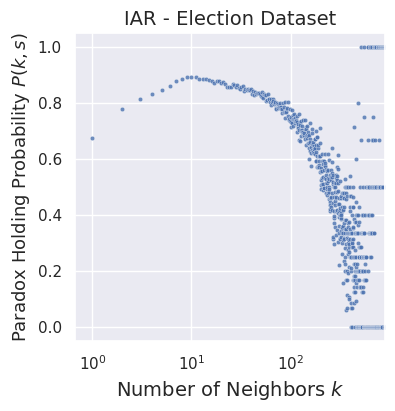

In [54]:
plt.figure(figsize=(4, 4))
sns.set(style='darkgrid')
sns.scatterplot(data=H_df, x='k_neighbors', y='H', alpha=0.8, s=10)  # Create the scatter plot
plt.xscale('log')
plt.xlim(0, 900)
plt.xlabel('Number of Neighbors $k$', fontsize=14)
plt.ylabel('Paradox Holding Probability $P(k,s)$', fontsize=13)
plt.title('IAR - Election Dataset', fontsize=14)
plt.savefig('img/GFP_IAR_election.png', dpi=300, bbox_inches='tight')
plt.show()

In [20]:
IAR_friend(filtered_interaction_df)

0.5477805649471044

In [21]:
IAR_friend(retweet_df)

0.5035310328988919

In [22]:
IAR_friend(mention_df)

0.5515014714706135

In [79]:
IAR_friend(shuffled_df)

0.5683307767396458

In [ ]:
iar_values = []

# Perform the shuffle and IAR_friend calculation 10 times
for _ in range(10):
    shuffled_referenced_userid = mention_df['referenced_userid'].sample(frac=1)
    shuffled_df = mention_df.copy()
    shuffled_df['referenced_userid'] = shuffled_referenced_userid.values
    iar = IAR_friend(shuffled_df)  # Assuming IAR_friend is a function that calculates some metric
    iar_values.append(iar)
    print(iar)

# Calculate the average of IAR_friend values
average_iar = np.mean(iar_values)

print("Average IAR_friend:", average_iar)

In [77]:
# Another shuffling - Edge swapping
def edge_swapping(df, num_swaps):
    """
    Perform edge swapping on a DataFrame representing a graph.
    df: DataFrame with columns ['userid', 'referenced_userid'] representing edges.
    num_swaps: Number of swaps to attempt.
    """
    for _ in tqdm(range(num_swaps)):
        # Select two rows (edges) at random
        idx = df.index.tolist()
        e1_idx, e2_idx = random.sample(idx, 2)
        e1, e2 = df.iloc[e1_idx], df.iloc[e2_idx]

        # Prepare potential swapped edges
        potential_swap_1 = (e1['userid'], e2['referenced_userid'])
        potential_swap_2 = (e2['userid'], e1['referenced_userid'])

        # Check if swapped edges already exist or would create self-loop
        conditions = [
            not ((df['userid'] == potential_swap_1[0]) & (df['referenced_userid'] == potential_swap_1[1])).any(),
            not ((df['userid'] == potential_swap_2[0]) & (df['referenced_userid'] == potential_swap_2[1])).any(),
            potential_swap_1[0] != potential_swap_1[1],
            potential_swap_2[0] != potential_swap_2[1]
        ]

        # If conditions are met, perform the swap
        if all(conditions):
            df.at[e1_idx, 'referenced_userid'] = potential_swap_1[1]
            df.at[e2_idx, 'referenced_userid'] = potential_swap_2[1]

    return df

# Perform edge swapping on the DataFrame
mention_df = mention_df.reset_index(drop=True)
num_swaps = 2000  # Number of swaps to attempt
shuffled_df = edge_swapping(mention_df.copy(), num_swaps)

100%|██████████| 2000/2000 [01:27<00:00, 22.80it/s]


In [68]:
def SAR_friend(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(SAR_df, on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_1'}, inplace=True)
    df = df.merge(SAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)

    grouped_df = df.groupby(['userid', 'SAR_1']).agg(
        k_neighbors=pd.NamedAgg(column='SAR_2', aggfunc='count'),
        SAR_2=pd.NamedAgg(column='SAR_2', aggfunc='mean')
    ).reset_index()
    grouped_df['FP'] = grouped_df['SAR_1'] < grouped_df['SAR_2']
    grouped_df['FP'] = grouped_df['FP'].astype(bool)
    H_df = grouped_df.groupby('k_neighbors')['FP'].agg(H=('mean'), count=('count')).reset_index()
    return (H_df['H'] * H_df['count']).sum() / H_df['count'].sum() #weighted average

In [18]:
def SAR_friend(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(SAR_df, on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_1'}, inplace=True)
    df = df.merge(SAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)

    grouped_df = df.groupby(['userid', 'SAR_1']).agg(
        k_neighbors=pd.NamedAgg(column='SAR_2', aggfunc='count'),
        SAR_2=pd.NamedAgg(column='SAR_2', aggfunc='mean')
    ).reset_index()
    grouped_df['FP'] = grouped_df['SAR_1'] < grouped_df['SAR_2']
    grouped_df['FP'] = grouped_df['FP'].astype(bool)
    H_df = grouped_df.groupby('k_neighbors')['FP'].agg(H=('mean'), count=('count')).reset_index()
    return H_df

In [40]:
def SAR_friend(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(SAR_df, on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_1'}, inplace=True)
    df = df.merge(SAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)

    grouped_df = df.groupby(['userid', 'SAR_1']).agg(
        k_neighbors=pd.NamedAgg(column='SAR_2', aggfunc='count'),
        SAR_2=pd.NamedAgg(column='SAR_2', aggfunc='mean')
    ).reset_index()
    grouped_df['FP'] = grouped_df['SAR_1'] < grouped_df['SAR_2']
    grouped_df['FP'] = grouped_df['FP'].astype(bool)
    return grouped_df

In [32]:
df = retweet_df.copy()
df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
df = df.merge(SAR_df, on='userid', how='left')
df.rename(columns={'SAR': 'SAR_1'}, inplace=True)
df = df.merge(SAR_df, left_on='referenced_userid', right_on='userid', how='left')
df.rename(columns={'SAR': 'SAR_2'}, inplace=True)
df.rename(columns={'userid_x': 'userid'}, inplace=True)
df

,userid,referenced_userid,count,1-SAR_x,SAR_1,userid_y,1-SAR_y,SAR_2
0,1000141948269678592,145354677,2,0.292683,0.707317,145354677,0.385714,0.614286
1,1000141948269678592,49118430,1,0.292683,0.707317,49118430,0.286713,0.713287
2,1000154893200576512,631540093,2,0.122222,0.877778,631540093,0.013158,0.986842
3,1000201182021730304,247054633,1,0.068966,0.931034,247054633,0.144928,0.855072
4,1000201182021730304,2567552643,1,0.068966,0.931034,2567552643,0.346939,0.653061
...,...,...,...,...,...,...,...,...
49674,999650963228123136,19880131,1,0.425926,0.574074,19880131,0.396739,0.603261
49675,99966080,7864222,1,0.041667,0.958333,7864222,0.074468,0.925532
49676,999672254727208960,350149869,1,0.064516,0.935484,350149869,0.125000,0.875000
49677,999797148333035520,1254046941643669504,1,0.112782,0.887218,1254046941643669504,0.237477,0.762523


In [33]:
df.to_csv("/scratch1/jinyiy/susceptibility_study_2/friendship_paradox/retweet_network_SAR_election.csv", index=False)

In [43]:
grouped_df = SAR_friend(mention_df)

correlation, p_value = spearmanr(grouped_df['SAR_1'], grouped_df['k_neighbors'])

print("Spearman correlation coefficient:", correlation)
print("P-value:", p_value)
#grouped_df.to_csv("/scratch1/jinyiy/susceptibility_study_2/friendship_paradox/p(k,s)_df_all_interaction_SAR_election.csv", index=False)

Spearman correlation coefficient: -0.0885400586348473
P-value: 7.436829297883942e-62


In [19]:
H_df = SAR_friend(interaction_df)
H_df.to_csv("/scratch1/jinyiy/susceptibility_study_2/friendship_paradox/H_df_all_SAR_covid.csv", index=False)

/tmp/SLURM_23036627/ipykernel_4477/2352912226.py:5: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0, 900)


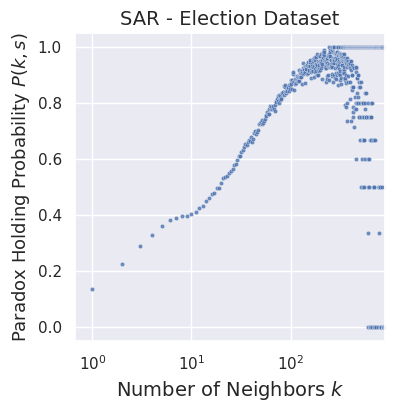

In [52]:
plt.figure(figsize=(4, 4))
sns.set(style='darkgrid')
sns.scatterplot(data=H_df, x='k_neighbors', y='H', alpha=0.8, s=10)  # Create the scatter plot
plt.xscale('log')
plt.xlim(0, 900)
plt.xlabel('Number of Neighbors $k$', fontsize=14)
plt.ylabel('Paradox Holding Probability $P(k,s)$', fontsize=13)
plt.title('SAR - Election Dataset', fontsize=14)
plt.savefig('img/GFP_SAR_election.png', dpi=300, bbox_inches='tight')
plt.show()

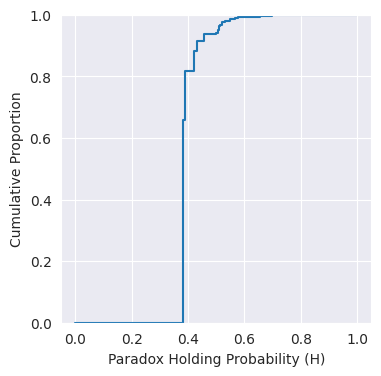

In [29]:
H_df = SAR_friend(interaction_df)

plt.figure(figsize=(4, 4))
sns.set_style("darkgrid")
sns.ecdfplot(data=H_df, x='H', weights='count', stat='proportion', complementary=False)
plt.xlabel('Paradox Holding Probability (H)')
plt.ylabel('Cumulative Proportion')
#plt.title('Cumulative Density Plot of Paradox Holding Probability (H)')
#plt.savefig('/home1/jinyiy/susceptibility/sus_study_2/img/SAR_individual_covid.png', bbox_inches='tight')
plt.show()

In [69]:
SAR_friend(filtered_interaction_df)

0.41871523612171446

In [70]:
SAR_friend(retweet_df)

0.5278750645920652

In [71]:
SAR_friend(mention_df)

0.3932969513414669

In [81]:
SAR_friend(shuffled_df)

0.36264119369683445

In [ ]:
sar_values = []

for _ in range(10):
    shuffled_referenced_userid = mention_df['referenced_userid'].sample(frac=1)
    shuffled_df = mention_df.copy()
    shuffled_df['referenced_userid'] = shuffled_referenced_userid.values
    sar = SAR_friend(shuffled_df)
    sar_values.append(sar)
    print(sar)

# Calculate the average of IAR_friend values
average_sar = np.mean(sar_values)

print("Average SAR_friend:", average_sar)

In [9]:
def IAR_follower(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(IAR_df, on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_1'}, inplace=True)
    df = df.merge(IAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)

    grouped_df = df.groupby(['referenced_userid', 'IAR_2']).agg(
        k_neighbors=pd.NamedAgg(column='IAR_1', aggfunc='count'),
        IAR_1=pd.NamedAgg(column='IAR_1', aggfunc='mean')
    ).reset_index()
    grouped_df['FP'] = grouped_df['IAR_2'] < grouped_df['IAR_1']
    grouped_df['FP'] = grouped_df['FP'].astype(bool)
    H_df = grouped_df.groupby('k_neighbors')['FP'].agg(H=('mean'), count=('count')).reset_index()
    return (H_df['H'] * H_df['count']).sum() / H_df['count'].sum()

In [10]:
IAR_follower(retweet_df)

0.7150089681545907

In [11]:
IAR_follower(quoted_df)

0.45836884598100136

In [12]:
IAR_follower(reply_df)

0.43869241182956276

In [13]:
IAR_follower(interaction_df)

0.5509364502598433

In [16]:
def SAR_follower(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(SAR_df, on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_1'}, inplace=True)
    df = df.merge(SAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)

    grouped_df = df.groupby(['referenced_userid', 'SAR_2']).agg(
        k_neighbors=pd.NamedAgg(column='SAR_1', aggfunc='count'),
        SAR_1=pd.NamedAgg(column='SAR_1', aggfunc='mean')
    ).reset_index()
    grouped_df['FP'] = grouped_df['SAR_2'] < grouped_df['SAR_1']
    grouped_df['FP'] = grouped_df['FP'].astype(bool)
    H_df = grouped_df.groupby('k_neighbors')['FP'].agg(H=('mean'), count=('count')).reset_index()
    return (H_df['H'] * H_df['count']).sum() / H_df['count'].sum()

In [17]:
SAR_follower(retweet_df)

0.19432806524755492

In [18]:
SAR_follower(quoted_df)

0.3904944910198199

In [19]:
SAR_follower(reply_df)

0.45449121435848766

In [20]:
SAR_follower(interaction_df)

0.37187725610229055

#### Network level

In [23]:
shuffled_referenced_userid = retweet_df['referenced_userid'].sample(frac=1, random_state=42)
shuffled_df = retweet_df.copy()
shuffled_df['referenced_userid'] = shuffled_referenced_userid.values

In [72]:
def IAR_friend(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(IAR_df, on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_1'}, inplace=True)
    df = df.merge(IAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)

    grouped_df = df.groupby(['userid', 'IAR_1']).agg(
        k_neighbors=pd.NamedAgg(column='IAR_2', aggfunc='count'),
        IAR_2=pd.NamedAgg(column='IAR_2', aggfunc='mean')
    ).reset_index()
    
    print('Individual mean:', grouped_df['IAR_1'].mean())
    print('Neighbor mean:', grouped_df['IAR_2'].mean())

    result = mannwhitneyu(grouped_df['IAR_1'], grouped_df['IAR_2'])
    print("Mann-Whitney U Test Statistic:", result.statistic)
    print("P-Value:", result.pvalue)

In [73]:
IAR_friend(filtered_interaction_df)

Individual mean: 0.00731425336503973
Neighbor mean: 0.008741657736338502
Mann-Whitney U Test Statistic: 922934861.0
P-Value: 1.5879811242002276e-225


In [74]:
IAR_friend(retweet_df)

Individual mean: 0.013297438874747899
Neighbor mean: 0.014119031692807642
Mann-Whitney U Test Statistic: 149115085.5
P-Value: 0.006342462579116606


In [75]:
IAR_friend(mention_df)

Individual mean: 0.00570462020226412
Neighbor mean: 0.007036835660844304
Mann-Whitney U Test Statistic: 523198454.0
P-Value: 7.181404794917731e-248


In [24]:
IAR_friend(shuffled_df)

Individual mean: 0.006638069360511841
Neighbor mean: 0.012992576117720154
Mann-Whitney U Test Statistic: 76070077209.0
P-Value: 0.0


In [76]:
def SAR_friend(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(SAR_df, on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_1'}, inplace=True)
    df = df.merge(SAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)

    grouped_df = df.groupby(['userid', 'SAR_1']).agg(
        k_neighbors=pd.NamedAgg(column='SAR_2', aggfunc='count'),
        SAR_2=pd.NamedAgg(column='SAR_2', aggfunc='mean')
    ).reset_index()
    print('Individual mean:', grouped_df['SAR_1'].mean())
    print('Neighbor mean:', grouped_df['SAR_2'].mean())

    result = mannwhitneyu(grouped_df['SAR_1'], grouped_df['SAR_2'])
    print("Mann-Whitney U Test Statistic:", result.statistic)
    print("P-Value:", result.pvalue)

In [77]:
SAR_friend(filtered_interaction_df)

Individual mean: 0.8744217678034444
Neighbor mean: 0.8628747827031175
Mann-Whitney U Test Statistic: 1132096697.5
P-Value: 2.935302758509978e-92


In [78]:
SAR_friend(retweet_df)

Individual mean: 0.8052834321017611
Neighbor mean: 0.8173705996987715
Mann-Whitney U Test Statistic: 142983788.0
P-Value: 1.9432723493009916e-20


In [79]:
SAR_friend(mention_df)

Individual mean: 0.8903614742559707
Neighbor mean: 0.8744070297561464
Mann-Whitney U Test Statistic: 679352600.5
P-Value: 1.4540171279647777e-140


In [29]:
SAR_friend(shuffled_df)

Individual mean: 0.8671525715098681
Neighbor mean: 0.8949719494187499
Mann-Whitney U Test Statistic: 179525179718.5
P-Value: 1.5984159493230712e-24


In [26]:
def IAR_follower(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(IAR_df, on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_1'}, inplace=True)
    df = df.merge(IAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'IAR': 'IAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)

    grouped_df = df.groupby(['referenced_userid', 'IAR_2']).agg(
        k_neighbors=pd.NamedAgg(column='IAR_1', aggfunc='count'),
        IAR_1=pd.NamedAgg(column='IAR_1', aggfunc='mean')
    ).reset_index()
    print('Individual mean:', grouped_df['IAR_2'].mean())
    print('Neighbor mean:', grouped_df['IAR_1'].mean())

    result = mannwhitneyu(grouped_df['IAR_2'], grouped_df['IAR_1'])
    print("Mann-Whitney U Test Statistic:", result.statistic)
    print("P-Value:", result.pvalue)

In [27]:
IAR_follower(retweet_df)

Individual mean: 0.006175576544992963
Neighbor mean: 0.009812936081658022
Mann-Whitney U Test Statistic: 5748500367.0
P-Value: 0.0


In [28]:
IAR_follower(quoted_df)

Individual mean: 0.007172727706579703
Neighbor mean: 0.006458897042918803
Mann-Whitney U Test Statistic: 1912991932.5
P-Value: 6.434199385980433e-144


In [29]:
IAR_follower(reply_df)

Individual mean: 0.005334130424584311
Neighbor mean: 0.003190452901439741
Mann-Whitney U Test Statistic: 40608804140.0
P-Value: 9.894773522249645e-14


In [30]:
IAR_follower(interaction_df)

Individual mean: 0.005477633377404813
Neighbor mean: 0.005271264132260192
Mann-Whitney U Test Statistic: 45525828968.5
P-Value: 0.0


In [31]:
def SAR_follower(df):
    df = df.groupby(['userid', 'referenced_userid']).size().reset_index(name='count')
    df = df.merge(SAR_df, on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_1'}, inplace=True)
    df = df.merge(SAR_df, left_on='referenced_userid', right_on='userid', how='left')
    df.rename(columns={'SAR': 'SAR_2'}, inplace=True)
    df.rename(columns={'userid_x': 'userid'}, inplace=True)

    grouped_df = df.groupby(['referenced_userid', 'SAR_2']).agg(
        k_neighbors=pd.NamedAgg(column='SAR_1', aggfunc='count'),
        SAR_1=pd.NamedAgg(column='SAR_1', aggfunc='mean')
    ).reset_index()
    print('Individual mean:', grouped_df['SAR_2'].mean())
    print('Neighbor mean:', grouped_df['SAR_1'].mean())

    result = mannwhitneyu(grouped_df['SAR_2'], grouped_df['SAR_1'])
    print("Mann-Whitney U Test Statistic:", result.statistic)
    print("P-Value:", result.pvalue)

In [32]:
SAR_follower(retweet_df)

Individual mean: 0.8964619554812046
Neighbor mean: 0.809662389275266
Mann-Whitney U Test Statistic: 16155888354.5
P-Value: 0.0


In [34]:
SAR_follower(quoted_df)

Individual mean: 0.8846871583756318
Neighbor mean: 0.8776057670398492
Mann-Whitney U Test Statistic: 2221631515.0
P-Value: 7.722394686402792e-99


In [35]:
SAR_follower(reply_df)

Individual mean: 0.8936623956164071
Neighbor mean: 0.9169289685670338
Mann-Whitney U Test Statistic: 39649249676.5
P-Value: 2.186610245132678e-116


In [36]:
SAR_follower(interaction_df)

Individual mean: 0.8945272227652569
Neighbor mean: 0.8855856800678071
Mann-Whitney U Test Statistic: 63520481152.0
P-Value: 0.0


### Linear Regression Model

In [43]:
IAR_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/IAR_score_election.csv")
IAR_df['userid'] = IAR_df['userid'].astype(str)
SAR_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/SAR_score_election.csv")
SAR_df['userid'] = SAR_df['userid'].astype(str)
IAR_users = set(IAR_df['userid'])
SAR_users = set(SAR_df['userid'])
target_users = IAR_users.intersection(SAR_users)
target_users = list(target_users)

#### Get user attributes

In [44]:
interaction_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/target_users_all_adoptions_election.csv", dtype=str)
interaction_df = interaction_df[['userid', 'referenced_userid', 'date', 'tweet_type']]
interaction_df = interaction_df[interaction_df['userid'].isin(target_users) & interaction_df['referenced_userid'].isin(target_users)]

In [45]:
pair_set = set(zip(interaction_df['userid'], interaction_df['referenced_userid']))
pair_set = {(a, b) for (a, b) in pair_set if a != b}
filtered_pairs_set = {(a, b) for (a, b) in pair_set if (b, a) in pair_set}
filtered_df = pd.DataFrame(filtered_pairs_set, columns=['userid', 'referenced_userid'])
filtered_interaction_df = interaction_df[
    interaction_df[['userid', 'referenced_userid']].apply(tuple, axis=1).isin(filtered_df.apply(tuple, axis=1))
]

In [46]:
filtered_interaction_df = pd.merge(filtered_interaction_df, IAR_df, on='userid', how='left')
filtered_interaction_df = filtered_interaction_df.rename(columns={'IAR': 'user_IAR'})
filtered_interaction_df = pd.merge(filtered_interaction_df, SAR_df, on='userid', how='left')
filtered_interaction_df = filtered_interaction_df.rename(columns={'1-SAR': 'user_SAR'})
filtered_interaction_df = filtered_interaction_df.drop('SAR', axis=1)

filtered_interaction_df = pd.merge(filtered_interaction_df, IAR_df, 
                                   left_on='referenced_userid', right_on='userid', how='left')
filtered_interaction_df = filtered_interaction_df.rename(columns={'IAR': 'friend_IAR'})
filtered_interaction_df = filtered_interaction_df.drop('userid_y', axis=1)
filtered_interaction_df = pd.merge(filtered_interaction_df, SAR_df, 
                                   left_on='referenced_userid', right_on='userid', how='left')
filtered_interaction_df = filtered_interaction_df.rename(columns={'1-SAR': 'friend_SAR'})
filtered_interaction_df = filtered_interaction_df.drop('SAR', axis=1)
filtered_interaction_df = filtered_interaction_df.drop('userid', axis=1)
filtered_interaction_df = filtered_interaction_df.rename(columns={'userid_x': 'userid'})

filtered_interaction_df['user_SAR'] = 1 - filtered_interaction_df['user_SAR']
filtered_interaction_df['friend_SAR'] = 1 - filtered_interaction_df['friend_SAR']

In [47]:
grouped_df = filtered_interaction_df.groupby('userid')[['user_IAR', 'user_SAR', 'friend_IAR', 'friend_SAR']].mean().reset_index()
grouped_df

,userid,user_IAR,user_SAR,friend_IAR,friend_SAR
0,1000075027,0.000000,1.000000,0.000000,1.000000
1,1000127207048728576,0.002133,0.933962,0.032120,0.598425
2,100013034,0.001237,0.904762,0.000081,0.991667
3,1000141948269678592,0.017824,0.707317,0.003800,0.654215
4,1000154893200576512,0.003489,0.877778,0.000022,0.986842
...,...,...,...,...,...
49789,999672254727208960,0.000882,0.935484,0.011533,0.875000
49790,999709727985750016,0.000000,1.000000,0.027178,0.601751
49791,999796014918778880,0.017162,0.875000,0.001875,0.936502
49792,999797148333035520,0.011666,0.887218,0.009705,0.793275


In [9]:
grouped_df.to_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/user_attribute/users_sus_metric_covid.csv")

#### Linear: Friend‘s IAR/SAR scores

In [11]:
grouped_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/user_attribute/users_sus_metric_election.csv")
X = grouped_df[['friend_IAR']]
y = grouped_df['user_SAR']

X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               user_SAR   R-squared:                       0.048
Model:                            OLS   Adj. R-squared:                  0.048
Method:                 Least Squares   F-statistic:                     2518.
Date:                Wed, 28 Aug 2024   Prob (F-statistic):               0.00
Time:                        21:25:26   Log-Likelihood:                 31273.
No. Observations:               49794   AIC:                        -6.254e+04
Df Residuals:                   49792   BIC:                        -6.252e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.8897      0.001   1457.597      0.0

In [12]:
X = grouped_df[['friend_IAR']]
y = grouped_df['user_IAR']
X_standardized = (X - X.mean()) / X.std()
y_standardized = (y - y.mean()) / y.std()
X_standardized = sm.add_constant(X_standardized)

model_standardized = sm.OLS(y_standardized, X_standardized).fit()

print(model_standardized.summary())

                            OLS Regression Results                            
Dep. Variable:               user_IAR   R-squared:                       0.293
Model:                            OLS   Adj. R-squared:                  0.293
Method:                 Least Squares   F-statistic:                 2.060e+04
Date:                Wed, 28 Aug 2024   Prob (F-statistic):               0.00
Time:                        21:25:32   Log-Likelihood:                -62033.
No. Observations:               49794   AIC:                         1.241e+05
Df Residuals:                   49792   BIC:                         1.241e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.523e-17      0.004   4.04e-15      1.0

#### Linear: Friend‘s IAR/SAR scores + user metadata

In [48]:
meta_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/user_attribute/users_metadata_election.csv")
meta_df['userid'] = meta_df['userid'].astype(str)

In [49]:
# normalize the data
meta_df['friends_count_normalized'] = (meta_df['friends_count'] - meta_df['friends_count'].min()) / (meta_df['friends_count'].max() - meta_df['friends_count'].min())
meta_df['followers_count_normalized'] = (meta_df['followers_count'] - meta_df['followers_count'].min()) / (meta_df['followers_count'].max() - meta_df['followers_count'].min())
meta_df['favourites_count_normalized'] = (meta_df['favourites_count'] - meta_df['favourites_count'].min()) / (meta_df['favourites_count'].max() - meta_df['favourites_count'].min())
meta_df['statuses_count_normalized'] = (meta_df['statuses_count'] - meta_df['statuses_count'].min()) / (meta_df['statuses_count'].max() - meta_df['statuses_count'].min())

In [50]:
new_df = pd.merge(filtered_interaction_df, 
                     meta_df[['userid', 'friends_count_normalized', 'followers_count_normalized',
                             'favourites_count_normalized', 'statuses_count_normalized']], 
                     on='userid', 
                     how='left')
new_df.rename(columns={'friends_count_normalized': 'user_friend_count'}, inplace=True)
new_df.rename(columns={'followers_count_normalized': 'user_followers_count'}, inplace=True)
new_df.rename(columns={'favourites_count_normalized': 'user_favourites_count'}, inplace=True)
new_df.rename(columns={'statuses_count_normalized': 'user_statuses_count'}, inplace=True)

In [51]:
new_df = pd.merge(new_df, 
                     meta_df[['userid', 'friends_count_normalized', 'followers_count_normalized',
                             'favourites_count_normalized', 'statuses_count_normalized']], 
                     left_on='referenced_userid', right_on='userid',
                     how='left')
new_df.rename(columns={'friends_count_normalized': 'friend_friend_count'}, inplace=True)
new_df.rename(columns={'followers_count_normalized': 'friend_followers_count'}, inplace=True)
new_df.rename(columns={'favourites_count_normalized': 'friend_favourites_count'}, inplace=True)
new_df.rename(columns={'statuses_count_normalized': 'friend_statuses_count'}, inplace=True)

In [52]:
grouped_df = new_df.groupby('userid_x')[['user_IAR', 'user_SAR', 'friend_IAR', 'friend_SAR',
                                                       'user_friend_count', 'user_followers_count', 'user_favourites_count', 'user_statuses_count', 
                                                       'friend_friend_count', 'friend_followers_count', 'friend_favourites_count', 'friend_statuses_count']].mean().reset_index()

In [53]:
grouped_df = grouped_df.dropna().reset_index(drop=True)

In [54]:
grouped_df

,userid_x,user_IAR,user_SAR,friend_IAR,friend_SAR,user_friend_count,user_followers_count,user_favourites_count,user_statuses_count,friend_friend_count,friend_followers_count,friend_favourites_count,friend_statuses_count
0,1000075027,0.000000,1.000000,0.000000,1.000000,0.000245,0.000001,0.001357,0.000900,0.000199,0.000002,0.033106,0.004861
1,100013034,0.001237,0.904762,0.000081,0.991667,0.000958,0.000013,0.074053,0.008954,0.000319,0.000004,0.014446,0.004028
2,1000141948269678592,0.017824,0.707317,0.003800,0.654215,0.036729,0.000642,0.051096,0.053263,0.010934,0.000185,0.049518,0.033704
3,1000154893200576512,0.003489,0.877778,0.000022,0.986842,0.007266,0.000123,0.019928,0.013372,0.001801,0.000011,0.001196,0.007237
4,1000155476418531328,0.000000,1.000000,0.006683,0.849359,0.003063,0.000038,0.007640,0.005009,0.047110,0.001013,0.156589,0.126135
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32963,999664767852625920,0.000160,0.970588,0.003567,0.895522,0.000177,0.000003,0.009305,0.009599,0.012132,0.000208,0.068858,0.018748
32964,999709727985750016,0.000000,1.000000,0.027178,0.601751,0.000070,0.000002,0.001364,0.001390,0.038998,0.000762,0.333751,0.249782
32965,999796014918778880,0.017162,0.875000,0.001875,0.936502,0.001736,0.000037,0.184140,0.014461,0.001472,0.000009,0.044891,0.022574
32966,999797148333035520,0.011666,0.887218,0.009705,0.793275,0.000645,0.000025,0.011788,0.016057,0.006742,0.000226,0.081772,0.085454


In [55]:
grouped_df.to_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/user_attribute/users_metadata_electionV2.csv")

In [56]:
grouped_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/user_attribute/users_metadata_electionV2.csv")

X = grouped_df[['friend_IAR', 'friend_SAR', 'user_friend_count', 'user_followers_count', 'user_favourites_count', 'user_statuses_count', 
                'friend_friend_count', 'friend_followers_count', 'friend_favourites_count', 'friend_statuses_count']]
y = grouped_df['user_IAR']

X_standardized = (X - X.mean()) / X.std()
y_standardized = (y - y.mean()) / y.std()
X_standardized = sm.add_constant(X_standardized)

model_standardized = sm.OLS(y_standardized, X_standardized).fit()

print(model_standardized.summary())

                            OLS Regression Results                            
Dep. Variable:               user_IAR   R-squared:                       0.385
Model:                            OLS   Adj. R-squared:                  0.385
Method:                 Least Squares   F-statistic:                     2061.
Date:                Wed, 28 Aug 2024   Prob (F-statistic):               0.00
Time:                        21:54:49   Log-Likelihood:                -38773.
No. Observations:               32968   AIC:                         7.757e+04
Df Residuals:                   32957   BIC:                         7.766e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                    5

In [24]:
# multicolinearity
X = grouped_df[['friend_IAR', 'friend_SAR', 'user_friend_count', 'user_followers_count', 'user_favourites_count', 'user_statuses_count', 
                'friend_friend_count', 'friend_followers_count', 'friend_favourites_count', 'friend_statuses_count']]

vif_data = pd.DataFrame() 
vif_data["feature"] = X.columns 
vif_data["VIF"] = [variance_inflation_factor(X.values, i) 
                          for i in range(len(X.columns))] 
print(vif_data)

                   feature       VIF
0               friend_IAR  1.065203
1               friend_SAR  1.781221
2        user_friend_count  1.218718
3     user_followers_count  1.024197
4    user_favourites_count  1.843554
5      user_statuses_count  1.893237
6      friend_friend_count  1.263132
7   friend_followers_count  1.049938
8  friend_favourites_count  1.952942
9    friend_statuses_count  1.981716


#### Linear: Friend‘s IAR/SAR scores + user metadata + network properties

In [57]:
new_df['userid'] = new_df['userid_x'].astype(str)
new_df['referenced_userid'] = new_df['referenced_userid'].astype(str)

In [58]:
G = nx.from_pandas_edgelist(new_df, 'userid', 'referenced_userid')

In [59]:
degree_centrality = nx.degree_centrality(G)
#betweenness_centrality = nx.betweenness_centrality(G)
#closeness_centrality = nx.closeness_centrality(G)
eigenvector_centrality = nx.eigenvector_centrality(G)
clustering_coefficient = nx.clustering(G)
pagerank = nx.pagerank(G)

df_degree = pd.DataFrame(list(degree_centrality.items()), columns=['userid', 'DegreeCentrality'])
# df_betweenness = pd.DataFrame(list(betweenness_centrality.items()), columns=['userid', 'BetweennessCentrality'])
# df_closeness = pd.DataFrame(list(closeness_centrality.items()), columns=['userid', 'ClosenessCentrality'])
df_eigenvector = pd.DataFrame(list(eigenvector_centrality.items()), columns=['userid', 'EigenvectorCentrality'])
df_clustering = pd.DataFrame(list(clustering_coefficient.items()), columns=['userid', 'ClusteringCoefficient'])
df_pagerank = pd.DataFrame(list(pagerank.items()), columns=['userid', 'PageRank'])

user_network = df_degree.merge(df_eigenvector, on='userid').merge(df_clustering, on='userid')\
                     .merge(df_pagerank, on='userid')

In [60]:
new_df = pd.merge(new_df, 
                     user_network[['userid', 'DegreeCentrality', 'EigenvectorCentrality',
                             'ClusteringCoefficient', 'PageRank']], 
                     on='userid', 
                     how='left')
new_df.rename(columns={'DegreeCentrality': 'user_DegreeCentrality'}, inplace=True)
new_df.rename(columns={'EigenvectorCentrality': 'user_EigenvectorCentrality'}, inplace=True)
new_df.rename(columns={'ClusteringCoefficient': 'user_ClusteringCoefficient'}, inplace=True)
new_df.rename(columns={'PageRank': 'user_PageRank'}, inplace=True)

In [61]:
new_df = new_df.drop(columns=['userid_x'])

In [62]:
new_df = pd.merge(new_df, 
                     user_network[['userid', 'DegreeCentrality', 'EigenvectorCentrality',
                             'ClusteringCoefficient', 'PageRank']], 
                     left_on='referenced_userid', right_on='userid',
                     how='left')
new_df.rename(columns={'DegreeCentrality': 'friend_DegreeCentrality'}, inplace=True)
new_df.rename(columns={'EigenvectorCentrality': 'friend_EigenvectorCentrality'}, inplace=True)
new_df.rename(columns={'ClusteringCoefficient': 'friend_ClusteringCoefficient'}, inplace=True)
new_df.rename(columns={'PageRank': 'friend_PageRank'}, inplace=True)

In [63]:
grouped_df = new_df.groupby('userid_x')[['user_IAR', 'user_SAR', 'friend_IAR', 'friend_SAR',
                                        'user_friend_count', 'user_followers_count', 'user_favourites_count', 'user_statuses_count', 
                                        'friend_friend_count', 'friend_followers_count', 'friend_favourites_count', 'friend_statuses_count',
                                        'user_DegreeCentrality', 'user_EigenvectorCentrality', 'user_ClusteringCoefficient', 'user_PageRank',
                                        'friend_DegreeCentrality', 'friend_EigenvectorCentrality', 'friend_ClusteringCoefficient', 'friend_PageRank'
                                        ]].mean().reset_index()

In [64]:
grouped_df = grouped_df.dropna().reset_index(drop=True)

In [65]:
grouped_df.rename(columns={'userid_x': 'userid'}, inplace=True)

In [66]:
grouped_df.to_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/user_attribute/users_metadata_electionV3.csv", index=False)

In [41]:
grouped_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/user_attribute/users_metadata_covidV3.csv")

X = grouped_df[['friend_IAR', 'friend_SAR', 'user_friend_count', 'user_followers_count', 'user_favourites_count', 'user_statuses_count', 
                'friend_friend_count', 'friend_followers_count', 'friend_favourites_count', 'friend_statuses_count',
                'user_DegreeCentrality', 'user_EigenvectorCentrality', 'user_ClusteringCoefficient', 
                'friend_DegreeCentrality', 'friend_EigenvectorCentrality', 'friend_ClusteringCoefficient']]
y = grouped_df['user_SAR']

X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               user_SAR   R-squared:                       0.233
Model:                            OLS   Adj. R-squared:                  0.233
Method:                 Least Squares   F-statistic:                     1012.
Date:                Wed, 28 Aug 2024   Prob (F-statistic):               0.00
Time:                        21:38:33   Log-Likelihood:                 38981.
No. Observations:               53337   AIC:                        -7.793e+04
Df Residuals:                   53320   BIC:                        -7.778e+04
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

In [42]:
# multicolinearity
X = grouped_df[['friend_IAR', 'friend_SAR', 'user_friend_count', 'user_followers_count', 'user_favourites_count', 'user_statuses_count', 
                'friend_friend_count', 'friend_followers_count', 'friend_favourites_count', 'friend_statuses_count',
                'user_DegreeCentrality', 'user_EigenvectorCentrality', 'user_ClusteringCoefficient', 
                'friend_DegreeCentrality', 'friend_EigenvectorCentrality', 'friend_ClusteringCoefficient']]

vif_data = pd.DataFrame() 
vif_data["feature"] = X.columns 
vif_data["VIF"] = [variance_inflation_factor(X.values, i) 
                          for i in range(len(X.columns))] 
print(vif_data)

                         feature       VIF
0                     friend_IAR  1.154322
1                     friend_SAR  2.077355
2              user_friend_count  1.258146
3           user_followers_count  1.024452
4          user_favourites_count  1.845669
5            user_statuses_count  1.912954
6            friend_friend_count  1.330677
7         friend_followers_count  1.050502
8        friend_favourites_count  1.957910
9          friend_statuses_count  2.013796
10         user_DegreeCentrality  1.619692
11    user_EigenvectorCentrality  1.826426
12    user_ClusteringCoefficient  2.026472
13       friend_DegreeCentrality  1.315390
14  friend_EigenvectorCentrality  1.751882
15  friend_ClusteringCoefficient  2.171108


### Random forrest regressor

In [13]:
grouped_df = pd.read_csv("/scratch1/jinyiy/susceptibility_study_2/user_attribute/linear_attribute_electionV2.csv")

X = grouped_df[['friend_IAR', 'friend_SAR', 'user_friend_count', 'user_followers_count', 'user_favourites_count', 'user_statuses_count', 
                'friend_friend_count', 'friend_followers_count', 'friend_favourites_count', 'friend_statuses_count',
                'user_DegreeCentrality', 'user_EigenvectorCentrality', 'user_ClusteringCoefficient', 
                'friend_DegreeCentrality', 'friend_EigenvectorCentrality', 'friend_ClusteringCoefficient']]
y = grouped_df['user_SAR']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_regressor = RandomForestRegressor(random_state=42)
rf_regressor.fit(X_train, y_train)

y_pred = rf_regressor.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
rf_regressor = RandomForestRegressor(random_state=42)

param_distributions = {
    'n_estimators': np.arange(100, 1001, 50),  # Number of trees in the forest
    'max_features': np.linspace(1, X_train.shape[1], 5, dtype=int),  # Number of features to consider at every split
    'max_depth': np.arange(10, 101, 10).tolist() + [None],  # Maximum number of levels in tree
    'min_samples_split': [2, 5, 10],  # Minimum number of samples required to split a node
    'min_samples_leaf': [1, 2, 4]  # Minimum number of samples required at each leaf node
}

random_search = RandomizedSearchCV(estimator=rf_regressor,
                                   param_distributions=param_distributions,
                                   n_iter=10,  # Number of parameter settings sampled
                                   cv=5,  # 3-fold cross-validation
                                   verbose=2, 
                                   random_state=42, 
                                   n_jobs=-1)  # Use all available cores

random_search.fit(X_train, y_train)
y_pred = random_search.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")
print("Best parameters:", random_search.best_params_)


In [12]:
sampled_X_test = X_test.sample(n=1000, replace=False)
explainer = shap.Explainer(random_search)
shap_values = explainer.shap_values(sampled_X_test)

TypeError: The passed model is not callable and cannot be analyzed directly with the given masker! Model: RandomizedSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42),
                   n_jobs=-1,
                   param_distributions={'max_depth': [10, 20, 30, 40, 50, 60,
                                                      70, 80, 90, 100, None],
                                        'max_features': array([ 1,  4,  8, 12, 16]),
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': array([ 100,  150,  200,  250,  300,  350,  400,  450,  500,  550,  600,
        650,  700,  750,  800,  850,  900,  950, 1000])},
                   random_state=42, verbose=2)

In [6]:
shap_values

array([[-5.88644170e-04,  6.72266144e-04, -8.80748600e-04, ...,
        -7.93200065e-05, -3.00528223e-04, -2.27931486e-04],
       [-2.50897231e-03, -2.83598233e-04, -2.21139664e-04, ...,
         2.07507619e-04, -1.61975996e-04, -1.70291332e-04],
       [-2.55274408e-03, -5.41459338e-05,  1.04022108e-03, ...,
         1.46266741e-03, -3.68653248e-04, -2.93700395e-04],
       ...,
       [-1.08756741e-03,  2.14421086e-04, -1.78295612e-04, ...,
         1.97565392e-04, -7.98712791e-05, -1.53647170e-04],
       [-2.66509682e-03, -1.03372958e-03, -5.37101328e-05, ...,
        -1.34043093e-05, -5.82051116e-04, -1.20457678e-04],
       [-2.07521127e-03,  7.13635802e-04, -8.26767036e-04, ...,
        -1.81280253e-05, -8.62401427e-04, -5.44606303e-05]])

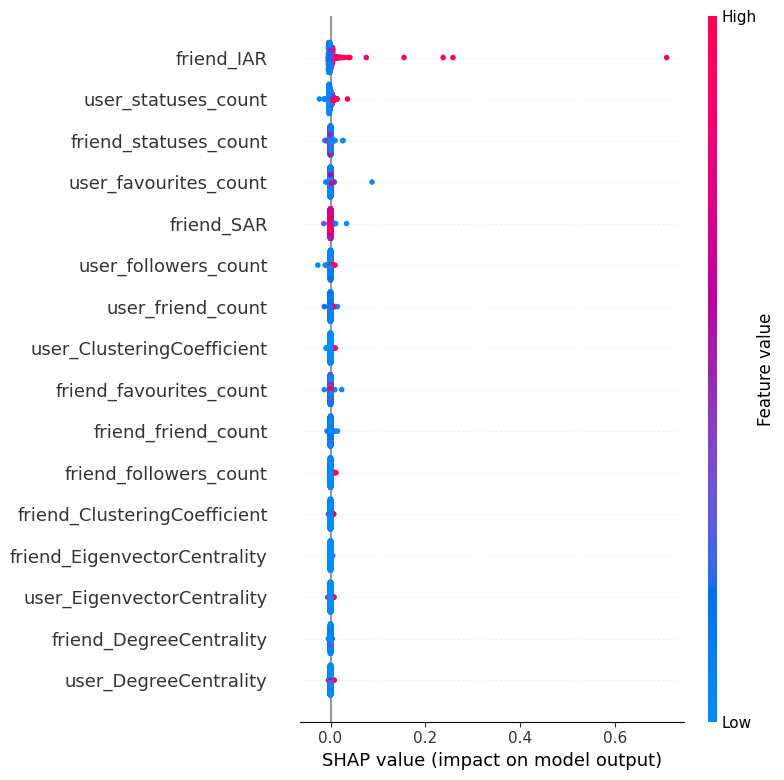

In [13]:
shap.summary_plot(shap_values, sampled_X_test)

In [19]:
Q1 = np.percentile(shap_values, 25, axis=0)
Q3 = np.percentile(shap_values, 75, axis=0)
IQR = Q3 - Q1

# Define bounds for outliers
lower_bound = Q1 - 1 * IQR
upper_bound = Q3 + 1 * IQR

# Create a mask to filter out outliers for each feature column
non_outlier_mask = (shap_values >= lower_bound) & (shap_values <= upper_bound)

# Apply the mask to filter out outliers - ensure all feature values in a row are within range
non_outlier_mask = non_outlier_mask.all(axis=1)
filtered_shap_values = shap_values[non_outlier_mask]

# Filter the rows in sampled_X_test based on the same mask
filtered_sampled_X_test = sampled_X_test.iloc[non_outlier_mask]

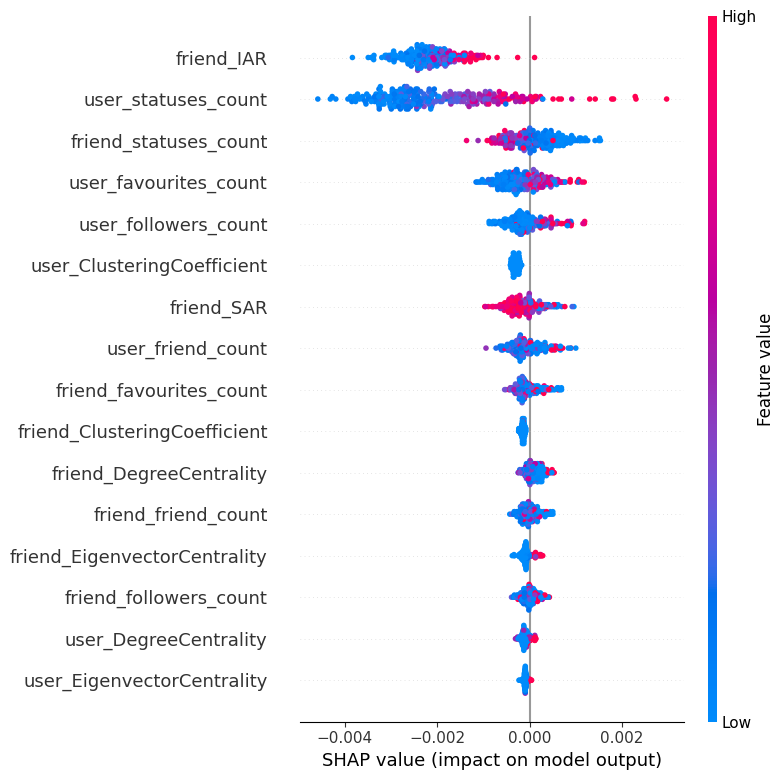

In [20]:
shap.summary_plot(filtered_shap_values, filtered_sampled_X_test)

### Sensitivity Analysis

#### User eigenvector centrality vs. IAR

In [9]:
df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/user_attribute/users_metadata_covidV3.csv")

correlation, p_value = pearsonr(df['User SAR'], df['User Degree Centrality'])
print("Pearson correlation:", correlation)
print("P-value:", p_value)

Pearson correlation: -0.2128019807959166
P-value: 0.0


#### Different target user URL thresholds

In [35]:
IAR_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/IAR_score_election.csv")
IAR_df['userid'] = IAR_df['userid'].astype(str)
SAR_df = pd.read_csv("/project/emiliofe_74/jinyiy/susceptibility_study_2/SAR_score_election.csv")
SAR_df['userid'] = SAR_df['userid'].astype(str)
IAR_users = set(IAR_df['userid'])
SAR_users = set(SAR_df['userid'])
target_users = IAR_users.intersection(SAR_users)
target_users = list(target_users)

In [36]:
with open('/project/emiliofe_74/jinyiy/susceptibility_study_2/target_users_election_over20.txt', 'r') as file:
    target_users_20 = file.readlines()
target_users_20 = [line.strip() for line in target_users_20]
target_users = list(set(target_users_20) & set(target_users))